# Garment Production Intelligence

## 02 — Manufacturing KPI Analysis

### Objective
Calculate manufacturing productivity KPIs to evaluate
production efficiency and identify performance gaps.

### Dataset
Cleaned Garment Worker Productivity Dataset.

In [23]:

import pandas as pd
from pathlib import Path

# Identify the project directory
project_dir = Path.cwd()

if project_dir.name == "notebooks":
    project_dir = project_dir.parent

# Locate cleaned dataset
file_path = (
    project_dir
    / "data"
    / "processed"
    / "garments_productivity_cleaned.csv"
)

# Load dataset
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")
print("Total rows:", df.shape[0])
print("Total columns:", df.shape[1])

df.head()


Dataset loaded successfully!
Total rows: 1197
Total columns: 15


,date,quarter,department,day,team,targeted_productivity,smv,wip,over_time,incentive,idle_time,idle_men,no_of_style_change,no_of_workers,actual_productivity
0,2015-01-01,Quarter1,sewing,Thursday,8,0.80,26.16,1108.0,7080,98,0.0,0,0,59.0,0.940725
1,2015-01-01,Quarter1,finishing,Thursday,1,0.75,3.94,NaN,960,0,0.0,0,0,8.0,0.886500
2,2015-01-01,Quarter1,sewing,Thursday,11,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
3,2015-01-01,Quarter1,sewing,Thursday,12,0.80,11.41,968.0,3660,50,0.0,0,0,30.5,0.800570
4,2015-01-01,Quarter1,sewing,Thursday,6,0.80,25.90,1170.0,1920,50,0.0,0,0,56.0,0.800382


In [24]:

# Calculate average productivity KPIs

avg_target = df["targeted_productivity"].mean()

avg_actual = df["actual_productivity"].mean()

productivity_gap = avg_actual - avg_target

print(f"Average Targeted Productivity: {avg_target:.2%}")

print(f"Average Actual Productivity: {avg_actual:.2%}")

print(
    f"Average Productivity Gap: "
    f"{productivity_gap * 100:+.2f} percentage points"
)


Average Targeted Productivity: 72.96%
Average Actual Productivity: 73.51%
Average Productivity Gap: +0.55 percentage points


In [25]:

# Calculate target achievement rate

df["target_achieved"] = (
    df["actual_productivity"] >= df["targeted_productivity"]
)

# Count observations
total_records = len(df)

achieved_records = df["target_achieved"].sum()

below_target_records = total_records - achieved_records

# Calculate target achievement rate
achievement_rate = (
    achieved_records / total_records
) * 100

print("Total Production Records:", total_records)

print("Records Meeting Target:", achieved_records)

print("Records Below Target:", below_target_records)

print(f"Target Achievement Rate: {achievement_rate:.2f}%")


Total Production Records: 1197
Records Meeting Target: 875
Records Below Target: 322
Target Achievement Rate: 73.10%


### KPI Interpretation — Target Achievement Rate

This KPI measures the percentage of production
observations that achieved or exceeded their
targeted productivity.

A higher achievement rate indicates that more
observations met their expected performance level.

This KPI will help management identify overall
production performance and compare departments
and teams.

In [26]:
df["target_achieved"] = (
    df["actual_productivity"] >= df["targeted_productivity"]
)

In [27]:

# Compare production performance by department

department_kpis = df.groupby("department").agg(
    total_records=("team", "size"),
    avg_target=("targeted_productivity", "mean"),
    avg_actual=("actual_productivity", "mean"),
    achieved_records=("target_achieved", "sum")
)

# Calculate productivity gap in percentage points
department_kpis["productivity_gap_pp"] = (
    department_kpis["avg_actual"]
    - department_kpis["avg_target"]
) * 100

# Calculate target achievement rate
department_kpis["achievement_rate"] = (
    department_kpis["achieved_records"]
    / department_kpis["total_records"]
) * 100

# Format productivity values as percentages
department_kpis["avg_target"] *= 100
department_kpis["avg_actual"] *= 100

# Display the results
department_kpis.round(2)


,total_records,avg_target,avg_actual,achieved_records,productivity_gap_pp,achievement_rate
department,,,,,,
finishing,506,73.74,75.3,302,1.56,59.68
sewing,691,72.40,72.2,573,-0.20,82.92


### Department Performance Analysis

This analysis compares productivity performance
between the sewing and finishing departments.

The main KPIs are:
- Average targeted productivity
- Average actual productivity
- Productivity gap
- Target achievement rate

The results will help identify which department
achieves production targets more consistently.

Note: Each record is a production observation,
not necessarily a unique production team.

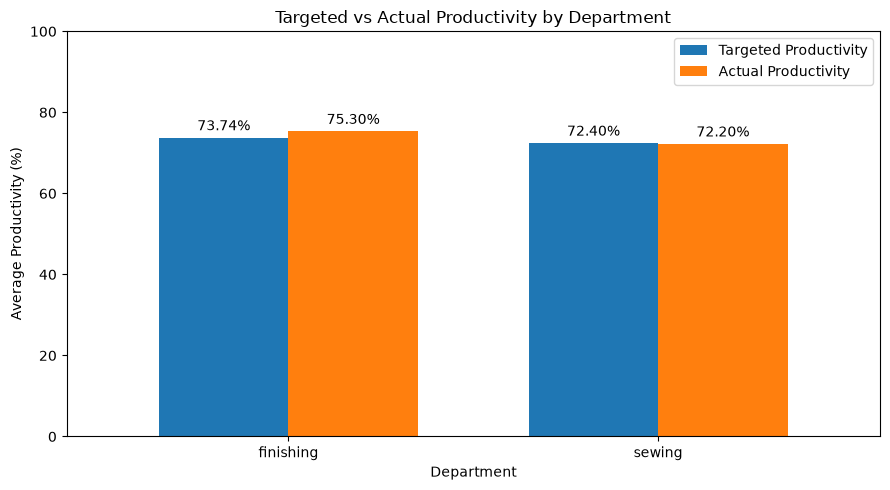

In [28]:

import matplotlib.pyplot as plt

# Select the department productivity KPIs
chart_data = department_kpis[
    ["avg_target", "avg_actual"]
].copy()

# Rename columns for the chart legend
chart_data.columns = [
    "Targeted Productivity",
    "Actual Productivity"
]

# Create a bar chart
ax = chart_data.plot(
    kind="bar",
    figsize=(9, 5),
    width=0.7
)

# Add chart title and labels
plt.title("Targeted vs Actual Productivity by Department")
plt.xlabel("Department")
plt.ylabel("Average Productivity (%)")

# Keep department names horizontal
plt.xticks(rotation=0)

# Add values above the bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.ylim(0, 100)
plt.legend()
plt.tight_layout()

# Display chart
plt.show()


### Business Interpretation

The finishing department recorded higher average
actual productivity than the sewing department.

Finishing achieved approximately 75.30% average
productivity against a target of 73.74%.

Sewing achieved approximately 72.20% average
productivity against a target of 72.40%.

These results indicate differences in average
performance between the two departments.

Further investigation is required to understand
the target achievement rates and the factors
associated with productivity differences.

In [29]:

# Calculate department target achievement rates

achievement_by_department = df.groupby("department").agg(
    total_records=("target_achieved", "size"),
    achieved_records=("target_achieved", "sum")
)

achievement_by_department["achievement_rate"] = (
    achievement_by_department["achieved_records"]
    / achievement_by_department["total_records"]
) * 100

print("Target Achievement Rate by Department:")

achievement_by_department.round(2)


Target Achievement Rate by Department:


,total_records,achieved_records,achievement_rate
department,,,
finishing,506,302,59.68
sewing,691,573,82.92


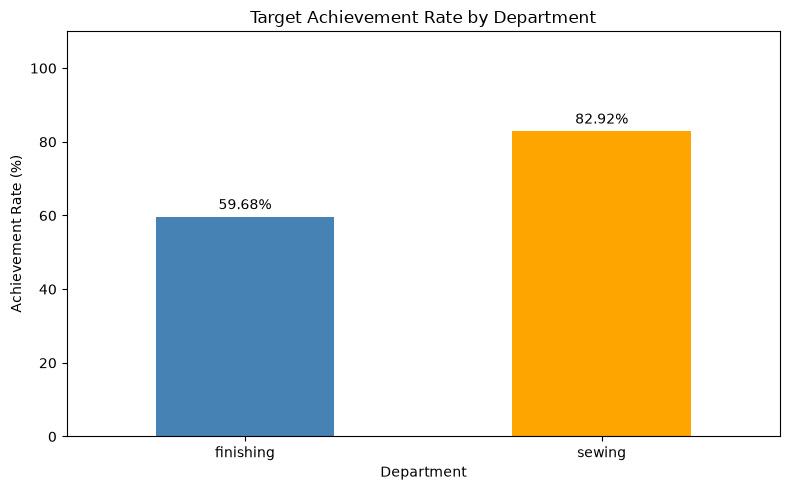

In [30]:

import matplotlib.pyplot as plt

# Create bar chart
ax = achievement_by_department["achievement_rate"].plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

plt.title("Target Achievement Rate by Department")
plt.xlabel("Department")
plt.ylabel("Achievement Rate (%)")

plt.xticks(rotation=0)
plt.ylim(0, 110)

# Display values above bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=3)

plt.tight_layout()
plt.show()


### Target Achievement Rate — Business Interpretation

This analysis compares how consistently the sewing
and finishing departments meet their productivity
targets.

The achievement rate represents the percentage
of production observations where actual productivity
was greater than or equal to targeted productivity.

The results help identify departments requiring
closer performance monitoring.

A department with higher average productivity
does not necessarily have a higher target
achievement rate.

In [31]:

# Print department target achievement results

print("DEPARTMENT TARGET ACHIEVEMENT REPORT")
print("-" * 45)

for department, row in achievement_by_department.iterrows():
    print(f"\nDepartment: {department.title()}")
    print(f"Total Records: {int(row['total_records'])}")
    print(f"Targets Achieved: {int(row['achieved_records'])}")
    print(f"Achievement Rate: {row['achievement_rate']:.2f}%")

# Identify department with highest achievement rate
best_department = achievement_by_department[
    "achievement_rate"
].idxmax()

print("\nHighest Achievement Rate:",
      best_department.title())


DEPARTMENT TARGET ACHIEVEMENT REPORT
---------------------------------------------

Department: Finishing
Total Records: 506
Targets Achieved: 302
Achievement Rate: 59.68%

Department: Sewing
Total Records: 691
Targets Achieved: 573
Achievement Rate: 82.92%

Highest Achievement Rate: Sewing
